In [126]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import RandomizedSearchCV, train_test_split
from sklearn.metrics import classification_report
from sklearn.utils.class_weight import compute_sample_weight
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

import joblib

df = pd.read_csv("telco_churn.csv")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [127]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

print(f"Valori non convertibili in numero: {df['TotalCharges'].isna().sum()}")
print(f"Anzianità di quei clienti: {df.loc[df['TotalCharges'].isna(), 'tenure'].unique()}")

df['TotalCharges'] = df['TotalCharges'].fillna(0)

Valori non convertibili in numero: 11
Anzianità di quei clienti: [0]


In [128]:
cat_cols = ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
num_cols = ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

In [129]:
X = df[num_cols + cat_cols]
y = df['Churn'].map({'Yes': 1, 'No': 0})

In [130]:
df['Churn'].value_counts(normalize=True)

Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64

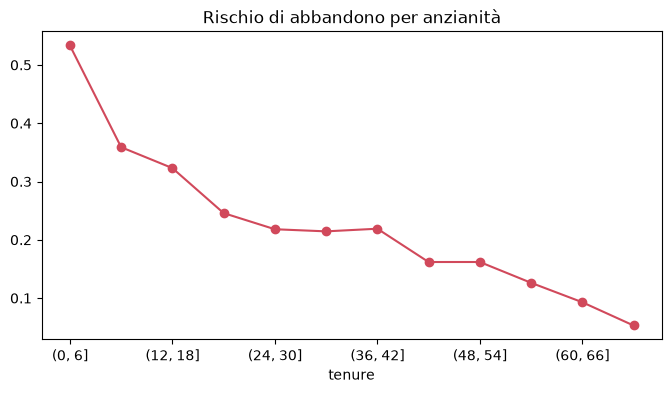

In [131]:
churn_by_tenure = df.groupby(pd.cut(df['tenure'], bins=range(0, 81, 6)))['Churn'].apply(lambda s: (s == 'Yes').mean())
churn_by_tenure.plot(marker='o', color='#d1495b', figsize=(8, 4), title='Rischio di abbandono per anzianità')
plt.show()

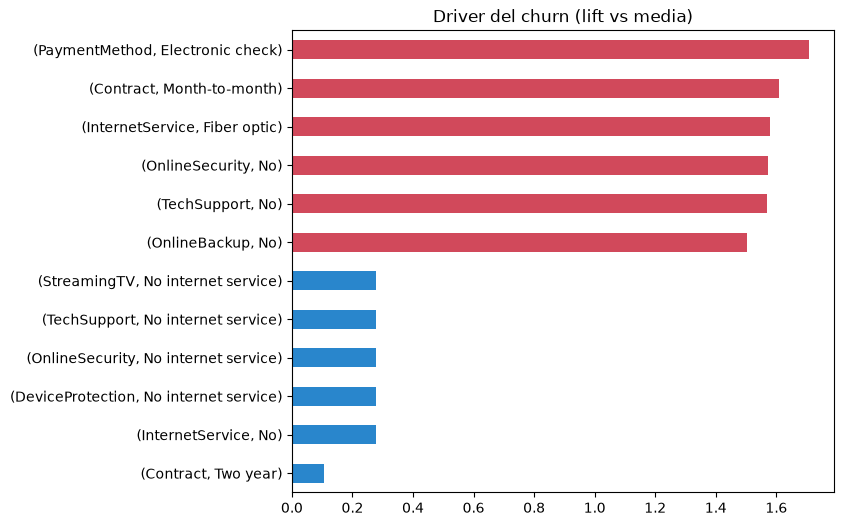

In [132]:
rates = pd.concat([df.groupby(c)['Churn'].apply(lambda s: (s == 'Yes').mean()) for c in cat_cols], keys=cat_cols)
top = (rates / df['Churn'].eq('Yes').mean()).sort_values().pipe(lambda s: pd.concat([s.head(6), s.tail(6)]))
top.plot.barh(color=['#2986cc' if v < 1 else '#d1495b' for v in top], figsize=(7, 6), title='Driver del churn (lift vs media)')
plt.show()

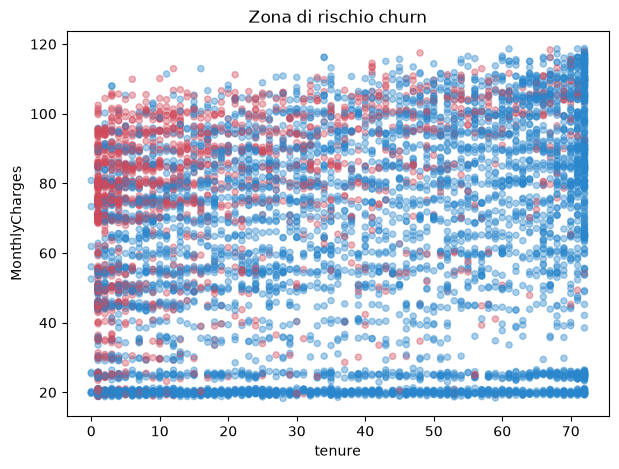

In [133]:
colors = df['Churn'].map({'Yes': '#d1495b', 'No': '#2986cc'})
df.plot.scatter(x='tenure', y='MonthlyCharges', c=colors, alpha=0.4, figsize=(7, 5), title='Zona di rischio churn')
plt.show()

In [134]:
X_train_raw, X_test_raw, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

In [135]:
weights = compute_sample_weight(class_weight='balanced', y=y_train)

In [136]:
one_hot = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
scaler = StandardScaler()

X_train = np.hstack([scaler.fit_transform(X_train_raw[num_cols]), one_hot.fit_transform(X_train_raw[cat_cols])])
X_test = np.hstack([scaler.transform(X_test_raw[num_cols]), one_hot.transform(X_test_raw[cat_cols])])

X_train.shape, X_test.shape

((5634, 45), (1409, 45))

In [137]:
log_reg = LogisticRegression(class_weight='balanced', random_state=42)
forest = RandomForestClassifier(n_estimators = 100, random_state=42, class_weight='balanced')
boosting = GradientBoostingClassifier(n_estimators = 100, random_state=42)

log_reg.fit(X_train, y_train)
forest.fit(X_train, y_train)
boosting.fit(X_train, y_train)

log_pred = log_reg.predict(X_test)
forest_pred = forest.predict(X_test)
boosting_pred = boosting.predict(X_test)

print(f'Regressione Logistica: {classification_report(y_test, log_pred)}')
print(f'Random Forest: {classification_report(y_test, forest_pred)}')
print(f'Gradient Boosting: {classification_report(y_test, boosting_pred)}')

Regressione Logistica:               precision    recall  f1-score   support

           0       0.90      0.72      0.80      1035
           1       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409

Random Forest:               precision    recall  f1-score   support

           0       0.86      0.82      0.84      1035
           1       0.56      0.63      0.59       374

    accuracy                           0.77      1409
   macro avg       0.71      0.73      0.72      1409
weighted avg       0.78      0.77      0.77      1409

Gradient Boosting:               precision    recall  f1-score   support

           0       0.84      0.91      0.87      1035
           1       0.67      0.52      0.58       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.73      1409
weighted avg     

In [138]:
param_dist = {
    'n_estimators': [100, 200, 300],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'max_depth': [2, 3, 4, 5],
    'min_samples_split': [2, 5, 10],
    'subsample': [0.7, 0.85, 1.0],
}

random_search = RandomizedSearchCV(
    GradientBoostingClassifier(random_state=42),
    param_dist, n_iter=20, cv=5, scoring='f1', random_state=42
)
random_search.fit(X_train, y_train, sample_weight=weights)

print(f"Migliori parametri: {random_search.best_params_}")
print(f"Miglior F1 in CV: {random_search.best_score_:.4f}")

Migliori parametri: {'subsample': 0.85, 'n_estimators': 100, 'min_samples_split': 5, 'max_depth': 2, 'learning_rate': 0.2}
Miglior F1 in CV: 0.7765


In [139]:
classifier = GradientBoostingClassifier(
    subsample=0.85,
    n_estimators=100,
    min_samples_split=5,
    max_depth=2,
    learning_rate=0.2,
    random_state=42,
)

classifier.fit(X_train, y_train, sample_weight=weights)
y_pred = classifier.predict(X_test)
report = classification_report(y_test, y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.91      0.72      0.81      1035
           1       0.51      0.79      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.74      0.76      1409



In [143]:
feature_names = ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'] + list(one_hot.get_feature_names_out(cat_cols))
importances = pd.Series(classifier.feature_importances_, index=feature_names).sort_values(ascending=False)

print("Le 12 colonne più usate dal modello (%)")
print((importances.head(12) * 100).round(2).to_string())

per_variabile = importances.groupby(importances.index.str.split('_').str[0]).sum().sort_values(ascending=False)
print("\nImportanza per variabile originale (%)")
print((per_variabile.head(8) * 100).round(2).to_string())

Le 12 colonne più usate dal modello (%)
Contract_Month-to-month           41.77
tenure                            12.02
InternetService_Fiber optic        8.50
OnlineSecurity_No                  8.10
TotalCharges                       7.35
MonthlyCharges                     5.85
Contract_Two year                  3.62
TechSupport_No                     3.02
PaymentMethod_Electronic check     2.89
PaperlessBilling_Yes               1.42
StreamingMovies_Yes                0.92
MultipleLines_No                   0.69

Importanza per variabile originale (%)
Contract           45.64
tenure             12.02
InternetService     8.70
OnlineSecurity      8.10
TotalCharges        7.35
MonthlyCharges      5.85
PaymentMethod       3.18
TechSupport         3.09


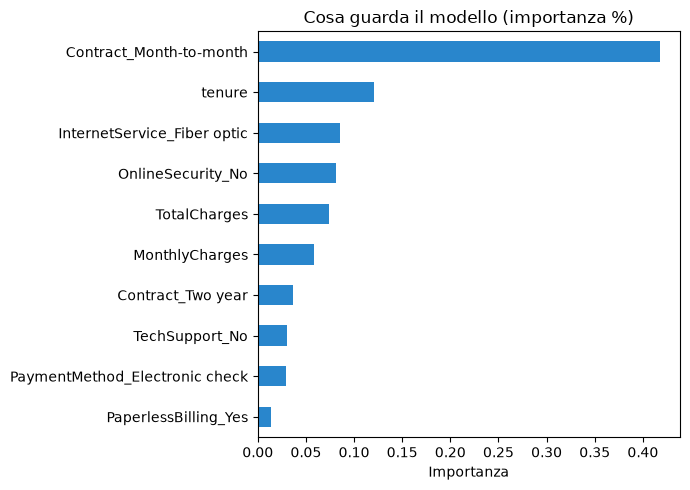

In [141]:
top = importances.head(10).sort_values()
top.plot.barh(color='#2986cc', figsize=(7, 5), title='Cosa guarda il modello (importanza %)')
plt.xlabel('Importanza')
plt.tight_layout()
plt.savefig('importanze.png', dpi=300)
plt.show()

In [142]:
joblib.dump(one_hot, 'app/models/encoder.pkl')
joblib.dump(scaler, 'app/models/scaler.pkl')
joblib.dump(classifier, 'app/models/classifier.pkl')

['app/models/classifier.pkl']